In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# load processed data from CSV file
df = pd.read_csv("../data/Processed_UICLibraryData.csv")
df
pivot = df.pivot(index="date", columns="floor", values="occupancy_count")

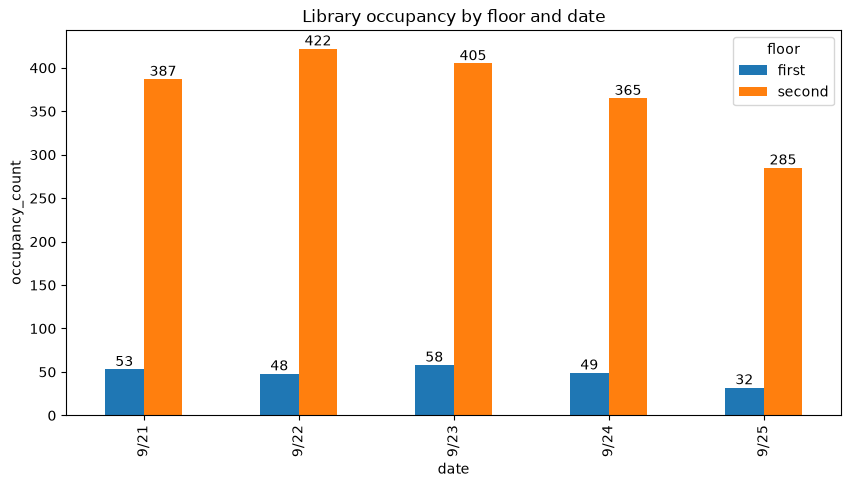

In [22]:
# direction 1
for i in pivot.plot(kind="bar", figsize=(10, 5)).containers:
    plt.bar_label(i)

plt.xlabel("date")
plt.ylabel("occupancy_count")
plt.title("Library occupancy by floor and date")
plt.show()

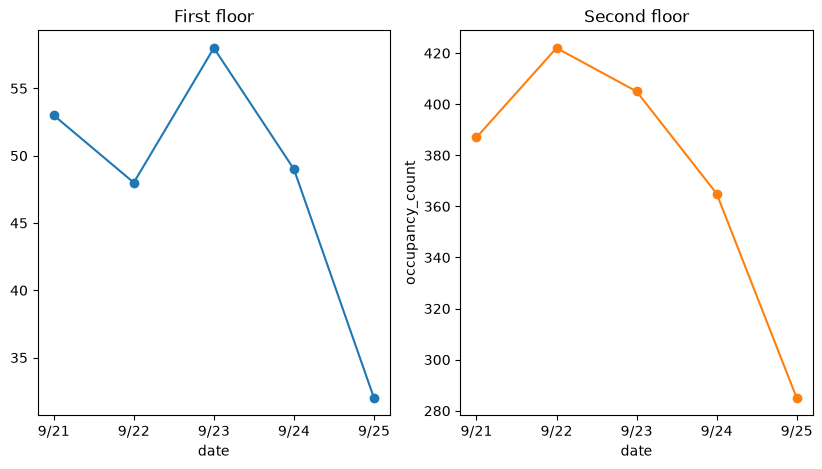

In [23]:
# direction 2
pivot.plot(kind="line", 
           marker="o", 
           subplots=True, 
           layout=(1, 2), 
           figsize=(10, 5), 
           legend=False, 
           title=["First floor", "Second floor"]
)

plt.xlabel("date")
plt.ylabel("occupancy_count")
plt.show()

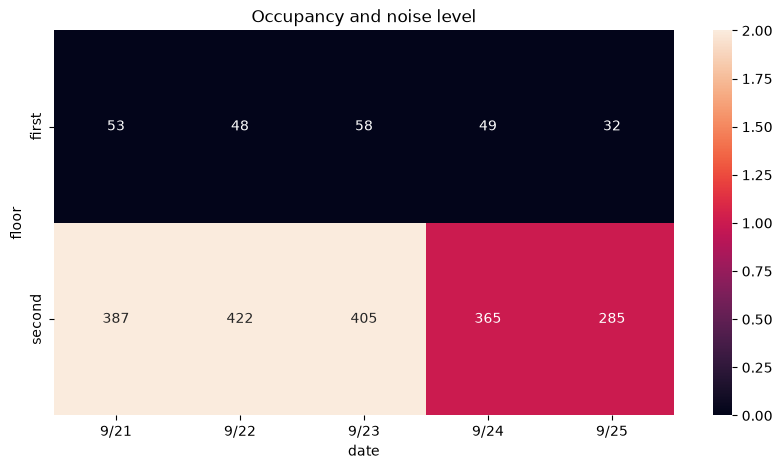

In [24]:
# direction 3
noise = df.pivot(
    index="floor", 
    columns="date", 
    values="noise_level"
)
occ = df.pivot(
    index="floor", 
    columns="date", 
    values="occupancy_count"
)

noise = noise.replace({
    "Quiet": 0,
    "Moderate": 1,
    "Noisy": 2
}).astype(float)

plt.figure(figsize=(10, 5))
sns.heatmap(noise, annot=occ, fmt=".0f")

plt.title("Occupancy and noise level")
plt.show()